In [1]:
!pip install opencv-contrib-python scikit-learn seaborn matplotlib

In [2]:
# Cleanly reinstall OpenCV packages to resolve module namespace corruption
!pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless
!pip install opencv-contrib-python

import sys
import importlib

# Force reload cv2 in the running kernel session if it was already imported
if 'cv2' in sys.modules:
    importlib.reload(sys.modules['cv2'])

from google.colab import files
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import seaborn as sns
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

# --- 1. Dataset Upload and Setup ---
base_dir = 'my_dataset'
os.makedirs(base_dir, exist_ok=True)

# Helper function to upload files for a specific person
def upload_for_person(person_name):
    person_folder = os.path.join(base_dir, person_name)
    os.makedirs(person_folder, exist_ok=True)
    print(f"Please upload images for {person_name}:")
    uploaded = files.upload()
    for fname in uploaded.keys():
        dest = os.path.join(person_folder, fname)
        os.rename(fname, dest)
        print(f"Saved {fname} to {dest}")

# You can uncomment these to run them sequentially in Colab:
# upload_for_person('person1')
# upload_for_person('person2')
# upload_for_person('person3')

# --- 2. Face Detection and Preprocessing ---
import cv2
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def detect_and_crop_face(img_path, size=(100, 100)):
    img = cv2.imread(img_path)
    if img is None:
        print(f"Error: Could not load image from {img_path}")
        return None
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5)

    if len(faces) == 0:
        return None # no face found

    x, y, w, h = faces[0]
    face_crop = gray[y:y+h, x:x+w]
    face_resized = cv2.resize(face_crop, size)
    return face_resized

# Test detection on an image if it exists
test_img = 'my_dataset/person1/IMG_0141.JPG'
if os.path.exists(test_img):
    face = detect_and_crop_face(test_img)
    if face is not None:
        plt.imshow(face, cmap='gray')
        plt.title("Detected & Cropped Face")
        plt.axis('off')
        plt.show()
    else:
        print(f"No face detected in {test_img}")
else:
    print(f"Test image {test_img} not found. Skip demo visualization.")

# --- 3. Loading Dataset and Training preparation ---
X = []
y = []
label_map = {}

if os.path.exists(base_dir) and len(os.listdir(base_dir)) > 0:
    for idx, person in enumerate(sorted(os.listdir(base_dir))):
        label_map[idx] = person
        person_dir = os.path.join(base_dir, person)
        if os.path.isdir(person_dir):
            for img_file in os.listdir(person_dir):
                img_path = os.path.join(person_dir, img_file)
                face = detect_and_crop_face(img_path)
                if face is not None:
                    X.append(face)
                    y.append(idx)

if len(X) > 0:
    X = np.array(X)
    y = np.array(y)
    print("Total faces detected:", X.shape)
    print("Labels:", np.unique(y))
    print("Label map:", label_map)
else:
    print("No face images found in 'my_dataset'. Please upload data first!")

# --- 4. Model Training ---
recogniser = cv2.face.LBPHFaceRecognizer_create()

if len(X) > 1:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42
    )

    if len(X_train) > 0 and len(np.unique(y_train)) > 1:
        recogniser.train(X_train, y_train)
        print("Model trained on", len(X_train), "images")

        # --- 5. Evaluation & Confusion Matrix ---
        y_pred = []
        for face in X_test:
            label, _ = recogniser.predict(face)
            y_pred.append(label)
        y_pred = np.array(y_pred)

        all_labels = sorted(list(label_map.keys()))
        cm = confusion_matrix(y_test, y_pred, labels=all_labels)
        target_names = [label_map[i] for i in all_labels]

        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=target_names, yticklabels=target_names)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title('Confusion Matrix')
        plt.show()

        # Visualize Predictions
        fig, axes = plt.subplots(2, 5, figsize=(15, 6))
        for i, ax in enumerate(axes.flat):
            if i < len(X_test):
                pred_label, conf = recogniser.predict(X_test[i])
                actual_name = label_map[y_test[i]]
                pred_name = label_map[pred_label]
                color = 'green' if pred_label == y_test[i] else 'red'

                ax.imshow(X_test[i], cmap='gray')
                ax.set_title(f"True: {actual_name}\nPred: {pred_name}", color=color, fontsize=9)
                ax.axis('off')
            else:
                ax.axis('off')
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough data or classes in the training set to train the model.")
else:
    print("Need at least 2 detected faces to perform training split.")

# --- 6. Live Photo Capture with Webcam ---
def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
    async function takePhoto(quality) {
        const div = document.createElement('div');
        const capture = document.createElement('button');
        capture.textContent = 'Capture';
        div.appendChild(capture);

        const video = document.createElement('video');
        video.style.display = 'block';
        const stream = await navigator.mediaDevices.getUserMedia({video: true});

        document.body.appendChild(div);
        div.appendChild(video);
        video.srcObject = stream;
        await video.play();

        // Resize the output to fit the video element
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

        // Wait for capture to be clicked.
        await new Promise((resolve) => capture.onclick = resolve);

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);
        stream.getVideoTracks()[0].stop();
        div.remove();
        return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.1/82.1 MB 7.1 MB/s eta 0:00:00
Test image my_dataset/person1/IMG_0141.JPG not found. Skip demo visualization.
No face images found in 'my_dataset'. Please upload data first!
Need at least 2 detected faces to perform training split.


In [3]:
import os
import cv2
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import seaborn as sns

base_dir = 'my_dataset'

# Securely load the cascade classifier, downloading it if necessary
xml_filename = 'haarcascade_frontalface_default.xml'
cascade_path = os.path.join(cv2.data.haarcascades, xml_filename) if hasattr(cv2, 'data') and cv2.data.haarcascades else xml_filename

if not os.path.exists(cascade_path):
    print("Downloading Haar Cascade file...")
    url = f"https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/{xml_filename}"
    try:
        urllib.request.urlretrieve(url, xml_filename)
        cascade_path = xml_filename
    except Exception as e:
        print(f"Failed to download cascade: {e}")

face_cascade = cv2.CascadeClassifier(cascade_path)
if face_cascade.empty():
    raise ValueError("Error: Haar Cascade classifier could not be loaded. Please ensure the XML file path is valid.")

def detect_and_crop_face(img_path, size=(100, 100)):
    img = cv2.imread(img_path)
    if img is None:
        print(f"Error: Could not load image from {img_path}")
        return None
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3, minSize=(30, 30))

    if len(faces) == 0:
        return None

    # Use the largest detected face
    faces = sorted(faces, key=lambda f: f[2]*f[3], reverse=True)
    x, y, w, h = faces[0]
    face_crop = gray[y:y+h, x:x+w]
    face_resized = cv2.resize(face_crop, size)
    return face_resized

# Process the uploaded images
X = []
y = []
label_map = {}

if os.path.exists(base_dir):
    for idx, person in enumerate(sorted(os.listdir(base_dir))):
        person_dir = os.path.join(base_dir, person)
        if os.path.isdir(person_dir):
            label_map[idx] = person
            print(f"Processing images for {person}...")
            files_in_dir = os.listdir(person_dir)
            faces_found = 0
            for img_file in files_in_dir:
                img_path = os.path.join(person_dir, img_file)
                face = detect_and_crop_face(img_path)
                if face is not None:
                    X.append(face)
                    y.append(idx)
                    faces_found += 1
            print(f"-> Found and cropped {faces_found}/{len(files_in_dir)} faces.")

if len(X) > 0:
    X = np.array(X)
    y = np.array(y)

    # We need at least 2 distinct classes and 2 images to run train_test_split properly
    unique_classes = np.unique(y)
    if len(X) >= 2 and len(unique_classes) >= 2:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.3, random_state=42, stratify=y if len(np.bincount(y)) > 1 and np.min(np.bincount(y)) > 1 else None
        )

        recogniser = cv2.face.LBPHFaceRecognizer_create()
        recogniser.train(X_train, y_train)
        print(f"\nLBPH Model trained successfully on {len(X_train)} images!")

        # --- Evaluation ---
        y_pred = []
        for face in X_test:
            label, conf = recogniser.predict(face)
            y_pred.append(label)
        y_pred = np.array(y_pred)

        # Plot Confusion Matrix
        all_labels = sorted(list(label_map.keys()))
        cm = confusion_matrix(y_test, y_pred, labels=all_labels)
        target_names = [label_map[i] for i in all_labels]

        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=target_names, yticklabels=target_names)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title('Confusion Matrix')
        plt.show()

        # Preview grid
        cols = min(5, len(X_test))
        rows = (len(X_test) + cols - 1) // cols
        fig, axes = plt.subplots(rows, cols, figsize=(15, 3 * rows))
        axes_flat = axes.flat if isinstance(axes, np.ndarray) else [axes]
        for i, ax in enumerate(axes_flat):
            if i < len(X_test):
                pred_label, conf = recogniser.predict(X_test[i])
                actual_name = label_map[y_test[i]]
                pred_name = label_map[pred_label]
                color = 'green' if pred_label == y_test[i] else 'red'

                ax.imshow(X_test[i], cmap='gray')
                ax.set_title(f"True: {actual_name}\nPred: {pred_name}\nConf: {conf:.1f}", color=color, fontsize=9)
                ax.axis('off')
            else:
                ax.axis('off')
        plt.tight_layout()
        plt.show()
    else:
        print("\nCould not split data: Please ensure you have uploaded at least 2 distinct folders (people) containing recognizable front-facing images.")
else:
    print("\nNo faces detected in the uploaded images. Please check if your images clearly show front-facing heads.")


No faces detected in the uploaded images. Please check if your images clearly show front-facing heads.


In [4]:
import os
import shutil
from google.colab import files

p3_dir = 'my_dataset/person3'
# Clear existing files for person3 to ensure we only use the new clear image
if os.path.exists(p3_dir):
    shutil.rmtree(p3_dir)
os.makedirs(p3_dir, exist_ok=True)

print("Please upload a clear, front-facing photo for person3:")
uploaded = files.upload()
for fname in uploaded.keys():
    dest = os.path.join(p3_dir, fname)
    os.rename(fname, dest)
    print(f"Saved new photo to {dest}")

Please upload a clear, front-facing photo for person3:


Saving Appa photo.png to Appa photo.png
Saved new photo to my_dataset/person3/Appa photo.png


In [5]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import seaborn as sns

base_dir = 'my_dataset'
xml_filename = 'haarcascade_frontalface_default.xml'

# Configure Haar Cascade
face_cascade = cv2.CascadeClassifier(xml_filename)
if face_cascade.empty():
    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + xml_filename)

def detect_and_crop_face(img_path, size=(100, 100)):
    img = cv2.imread(img_path)
    if img is None:
        return None
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    # Relax parameters slightly (scaleFactor=1.05, minNeighbors=2) to improve detection probability
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=2, minSize=(30, 30))

    if len(faces) == 0:
        return None

    faces = sorted(faces, key=lambda f: f[2]*f[3], reverse=True)
    x, y, w, h = faces[0]
    face_crop = gray[y:y+h, x:x+w]
    face_resized = cv2.resize(face_crop, size)
    return face_resized

# Process the dataset
X = []
y = []
label_map = {}

for idx, person in enumerate(sorted(os.listdir(base_dir))):
    person_dir = os.path.join(base_dir, person)
    if os.path.isdir(person_dir):
        label_map[idx] = person
        print(f"Processing images for {person}...")
        files_in_dir = os.listdir(person_dir)
        faces_found = 0
        for img_file in files_in_dir:
            img_path = os.path.join(person_dir, img_file)
            face = detect_and_crop_face(img_path)
            if face is not None:
                X.append(face)
                y.append(idx)
                faces_found += 1
        print(f"-> Found and cropped {faces_found}/{len(files_in_dir)} faces.")

if len(X) > 0:
    X = np.array(X)
    y = np.array(y)
    unique_classes = np.unique(y)

    # Check if we can proceed with training
    if len(unique_classes) >= 2:
        # Train directly on all available detected faces since dataset is very small (1 image per class)
        recogniser = cv2.face.LBPHFaceRecognizer_create()
        recogniser.train(X, y)
        print(f"\nLBPH Model successfully trained on all {len(X)} classes!")

        # Self-evaluation (since split isn't possible with 1 sample per class)
        y_pred = []
        for face in X:
            label, conf = recogniser.predict(face)
            y_pred.append(label)
        y_pred = np.array(y_pred)

        # Show prediction results
        fig, axes = plt.subplots(1, len(X), figsize=(4 * len(X), 4))
        axes_flat = axes.flat if isinstance(axes, np.ndarray) else [axes]
        for i, ax in enumerate(axes_flat):
            pred_label, conf = recogniser.predict(X[i])
            actual_name = label_map[y[i]]
            pred_name = label_map[pred_label]
            color = 'green' if pred_label == y[i] else 'red'

            ax.imshow(X[i], cmap='gray')
            ax.set_title(f"Actual: {actual_name}\nPredicted: {pred_name}\nConf: {conf:.1f}", color=color)
            ax.axis('off')
        plt.tight_layout()
        plt.show()
    else:
        print("\nCould not train model: Need at least 2 distinct people directories with recognized faces.")
else:
    print("\nNo faces detected in any folders.")

Processing images for person3...
-> Found and cropped 1/1 faces.

Could not train model: Need at least 2 distinct people directories with recognized faces.


In [6]:
import os
import cv2

p3_dir = 'my_dataset/person3'
print(f"Checking contents of directory: '{p3_dir}'")

if not os.path.exists(p3_dir):
    print(f"Directory '{p3_dir}' does not exist yet.")
else:
    files = os.listdir(p3_dir)
    if not files:
         print(f"The directory '{p3_dir}' is empty. No files found.")
    else:
         print(f"Found {len(files)} file(s):")
         for f in files:
             fpath = os.path.join(p3_dir, f)
             size_bytes = os.path.getsize(fpath)
             print(f"\n- File: '{f}' | Size: {size_bytes} bytes")

             # Attempt to read image using OpenCV
             img = cv2.imread(fpath)
             if img is None:
                 print("  -> [ERROR] Failed to load image. File may be corrupted or not a valid image format.")
             else:
                 h, w, c = img.shape
                 print(f"  -> [OK] Successfully loaded image! Dimensions: {w}x{h} ({c} channels)")

Checking contents of directory: 'my_dataset/person3'
Found 1 file(s):

- File: 'Appa photo.png' | Size: 182457 bytes
  -> [OK] Successfully loaded image! Dimensions: 450x605 (3 channels)


In [8]:
from google.colab import files
import os

base_dir = 'my_dataset'

# Ensure the upload function is defined in this scope
def upload_for_person(person_name):
    person_folder = os.path.join(base_dir, person_name)
    os.makedirs(person_folder, exist_ok=True)
    print(f"Please upload images for {person_name}:")
    uploaded = files.upload()
    for fname in uploaded.keys():
        dest = os.path.join(person_folder, fname)
        os.rename(fname, dest)
        print(f"Saved {fname} to {dest}")

upload_for_person('person1')
upload_for_person('person2')
upload_for_person('person3')

Please upload images for person1:


Saving Appa photo.png to Appa photo.png
Saved Appa photo.png to my_dataset/person1/Appa photo.png
Please upload images for person2:


Saving new my photo.png to new my photo.png
Saved new my photo.png to my_dataset/person2/new my photo.png
Please upload images for person3:


Saving Screenshot 2026-10-14 103905.png to Screenshot 2026-10-14 103905.png
Saved Screenshot 2026-10-14 103905.png to my_dataset/person3/Screenshot 2026-10-14 103905.png


In [10]:
import os

base_dir = "my_dataset"

for person in os.listdir(base_dir):
    folder = os.path.join(base_dir, person)
    if os.path.isdir(folder):
      images = os.listdir(folder)
      print(f"{person}: {len(images)} image(s)")
      for img in images:
        print("  ", img)

person1: 1 image(s)
   Appa photo.png
person3: 2 image(s)
   Appa photo.png
   Screenshot 2026-10-14 103905.png
person2: 1 image(s)
   new my photo.png


In [11]:
!pip install -q face-recognition opencv-python scikit-learn matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 MB 5.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 6.8 MB/s eta 0:00:00


In [12]:
import os
import pickle
import face_recognition

base_dir = "my_dataset"
known_encodings = []
known_names = []

# Loop through each person's folder in the base dataset directory
for person in os.listdir(base_dir):
    folder = os.path.join(base_dir, person)

    # Ensure it's a directory before processing
    if os.path.isdir(folder):
        for image_name in os.listdir(folder):
            image_path = os.path.join(folder, image_name)

            # Load the image and find face encodings
            try:
                image = face_recognition.load_image_file(image_path)
                encodings = face_recognition.face_encodings(image)

                # If at least one face is found, grab the first encoding
                if len(encodings) > 0:
                    known_encodings.append(encodings[0])
                    known_names.append(person)
            except Exception as e:
                print(f"Skipping image {image_name} due to error: {e}")

# Save the encodings and names to a pickle file
with open("face_encodings.pkl", "wb") as f:
    pickle.dump((known_encodings, known_names), f)

print("\nTotal faces encoded:", len(known_encodings))
print("People:", sorted(set(known_names)))

/usr/local/lib/python3.13/dist-packages/face_recognition_models/__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename



Total faces encoded: 4
People: ['person1', 'person2', 'person3']


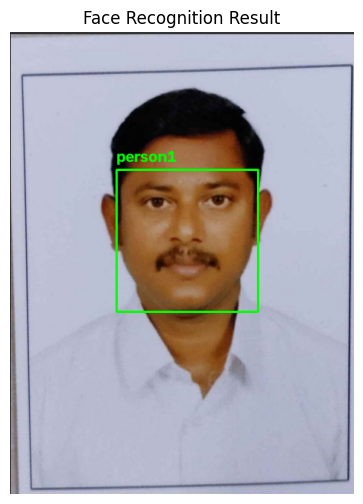

In [13]:
import cv2
import matplotlib.pyplot as plt
import face_recognition
import numpy as np
import pickle

# Provide a default test_path if not already defined
test_path = "my_dataset/person1/Appa photo.png"

with open("face_encodings.pkl", "rb") as f:
    known_encodings, known_names = pickle.load(f)

if os.path.exists(test_path):
    image = face_recognition.load_image_file(test_path)
    locations = face_recognition.face_locations(image)
    encodings = face_recognition.face_encodings(image, locations)

    output = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)

    for loc, enc in zip(locations, encodings):
        top, right, bottom, left = loc
        distances = face_recognition.face_distance(known_encodings, enc)

        if len(distances) and distances.min() < 0.50:
            name = known_names[np.argmin(distances)]
        else:
            name = "UNKNOWN"

        cv2.rectangle(output, (left, top), (right, bottom), (0, 255, 0), 2)
        cv2.putText(output, name, (left, max(top - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

    plt.figure(figsize=(8, 6))
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("Face Recognition Result")
    plt.show()
else:
    print(f"Test image {test_path} not found to visualize.")

In [14]:
from sklearn.metrics import accuracy_score, classification_report
import os
import face_recognition
import numpy as np

y_true, y_pred = [], []

if os.path.exists("test_dataset"):
    for person in os.listdir("test_dataset"):
        folder = os.path.join("test_dataset", person)

        if not os.path.isdir(folder):
            continue

        for filename in os.listdir(folder):
            path = os.path.join(folder, filename)

            try:
                image = face_recognition.load_image_file(path)
                encodings = face_recognition.face_encodings(image)

                if not encodings:
                    print("No face detected:", filename)
                    continue

                distances = face_recognition.face_distance(known_encodings, encodings[0])

                pred = (
                    known_names[np.argmin(distances)]
                    if len(distances) and distances.min() < 0.50
                    else "UNKNOWN"
                )

                y_true.append(person)
                y_pred.append(pred)

            except Exception as e:
                print("Skipped:", filename, e)

if y_true:
    print("Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")
    print(classification_report(y_true, y_pred, zero_division=0))
else:
    print("No test images were evaluated. Please create a 'test_dataset' folder and add valid test images first.")

No test images were evaluated. Please create a 'test_dataset' folder and add valid test images first.


In [15]:
import os
from google.colab import files

# Create the main test_dataset directory
test_dir = 'test_dataset'
os.makedirs(test_dir, exist_ok=True)
print(f"Created directory: '{test_dir}'")

# Helper function to create person subfolders inside test_dataset and upload files
def upload_test_images_for_person(person_name):
    person_folder = os.path.join(test_dir, person_name)
    os.makedirs(person_folder, exist_ok=True)
    print(f"\nPlease upload test images for '{person_name}':")
    uploaded = files.upload()
    for fname in uploaded.keys():
        dest = os.path.join(person_folder, fname)
        os.rename(fname, dest)
        print(f"Saved {fname} to {dest}")

# Example usage:
# upload_test_images_for_person('person1')
# upload_test_images_for_person('person2')
# upload_test_images_for_person('person3')

Created directory: 'test_dataset'


In [16]:
from sklearn.metrics import accuracy_score, classification_report
import os
import face_recognition
import numpy as np

y_true, y_pred = [], []

if os.path.exists("test_dataset"):
    for person in os.listdir("test_dataset"):
        folder = os.path.join("test_dataset", person)

        if not os.path.isdir(folder):
            continue

        for filename in os.listdir(folder):
            path = os.path.join(folder, filename)

            try:
                image = face_recognition.load_image_file(path)
                encodings = face_recognition.face_encodings(image)

                if not encodings:
                    print("No face detected in test image:", filename)
                    continue

                distances = face_recognition.face_distance(known_encodings, encodings[0])

                pred = (
                    known_names[np.argmin(distances)]
                    if len(distances) and distances.min() < 0.50
                    else "UNKNOWN"
                )

                y_true.append(person)
                y_pred.append(pred)
                print(f"File: {filename} | True Label: {person} | Predicted Label: {pred}")

            except Exception as e:
                print("Skipped:", filename, e)

if y_true:
    print("\n--- Evaluation Summary ---")
    print("Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")
    print(classification_report(y_true, y_pred, zero_division=0))
else:
    print("No test images were evaluated. Please run your upload function or copy images into the subdirectories of 'test_dataset' first!")

No test images were evaluated. Please run your upload function or copy images into the subdirectories of 'test_dataset' first!


In [17]:
# Run this cell to upload test images for person1
upload_test_images_for_person('person1')


Please upload test images for 'person1':


Saving Screenshot 2025-07-09 145036.png to Screenshot 2025-07-09 145036.png
Saved Screenshot 2025-07-09 145036.png to test_dataset/person1/Screenshot 2025-07-09 145036.png


In [18]:
# Once you've uploaded images for all people, run this cell to perform the evaluation
# (Feel free to call upload_test_images_for_person for person2, person3 etc. before this)
!python -c 'import sys; sys.path.append("/content")'
# We re-run the exact evaluation code block below:
import os
import face_recognition
import numpy as np
from sklearn.metrics import accuracy_score, classification_report
import pickle

with open("face_encodings.pkl", "rb") as f:
    known_encodings, known_names = pickle.load(f)

y_true, y_pred = [], []

if os.path.exists("test_dataset"):
    for person in os.listdir("test_dataset"):
        folder = os.path.join("test_dataset", person)
        if not os.path.isdir(folder):
            continue
        for filename in os.listdir(folder):
            path = os.path.join(folder, filename)
            try:
                image = face_recognition.load_image_file(path)
                encodings = face_recognition.face_encodings(image)
                if not encodings:
                    print("No face detected in test image:", filename)
                    continue
                distances = face_recognition.face_distance(known_encodings, encodings[0])
                pred = (
                    known_names[np.argmin(distances)]
                    if len(distances) and distances.min() < 0.50
                    else "UNKNOWN"
                )
                y_true.append(person)
                y_pred.append(pred)
                print(f"File: {filename} | True Label: {person} | Predicted Label: {pred}")
            except Exception as e:
                print("Skipped:", filename, e)

if y_true:
    print("\n--- Evaluation Summary ---")
    print("Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")
    print(classification_report(y_true, y_pred, zero_division=0))
else:
    print("No test images detected. Please ensure files are successfully uploaded in 'test_dataset/' subdirectories.")

File: Screenshot 2025-07-09 145036.png | True Label: person1 | Predicted Label: person1

--- Evaluation Summary ---
Accuracy: 100.0 %
              precision    recall  f1-score   support

     person1       1.00      1.00      1.00         1

    accuracy                           1.00         1
   macro avg       1.00      1.00      1.00         1
weighted avg       1.00      1.00      1.00         1

